# Maxi: medición, estadística y análisis

Pruebas de `src/measurement.py` y `src/analysis.py` (ítems 2 a 5 de `docs/task_split.md`).

Como todavía no hay ansatz optimizado, se usan tres estados de prueba de 8 qubits sobre el hamiltoniano real de H₄ a 2,4 Å:

- **HF**: el determinante de Hartree-Fock (las `X` en los qubits ocupados).
- **mix**: HF más rotaciones `ry` al azar y una cadena de `cx`. Es un estado genérico, que **no** es autoestado ni conserva N.
- **FCI**: el estado fundamental exacto, cargado con `initialize`. **Solo para probar**: la consigna no deja usarlo como resultado, pero sirve porque sabemos qué tiene que dar (N = 4, S² = 0, Var(H) = 0).

Los valores "exactos" se calculan con `Statevector` únicamente para comparar.

In [1]:
import sys, time
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from hamiltonian import build_problem, DISTANCES
from measurement import (measure_energy, measure_expectation, validate_sigma,
                         compare_allocations, shots_for_sigma, measure_reliability)
from analysis import make_record, report, results_table, beats_ccsd, plot_errors

pd.set_option("display.precision", 5)
%matplotlib inline

In [2]:
p = build_problem(2.4)
H = p["hamiltonian"]
print(f"{len(H)} términos de Pauli, {len(H.group_commuting(qubit_wise=True))} grupos que conmutan qubit a qubit")

def hf_circuit(problem):
    qc = QuantumCircuit(problem["n_qubits"])
    for q, bit in enumerate(problem["hf_bitstring"][::-1]):   # qubit 0 = carácter de la derecha
        if bit == "1":
            qc.x(q)
    return qc

qc_hf = hf_circuit(p)

qc_mix = qc_hf.copy()
rng = np.random.default_rng(1)
for q in range(8):
    qc_mix.ry(rng.uniform(-0.4, 0.4), q)
for q in range(7):
    qc_mix.cx(q, q + 1)

# estado fundamental exacto en el sector N = 4, S² = 0 (solo para probar)
Hm, Nm, S2m = (p[k].to_matrix() for k in ("hamiltonian", "number_op", "s2_op"))
I = np.eye(Hm.shape[0])
_, vecs = np.linalg.eigh(Hm + 10 * (Nm - 4 * I) @ (Nm - 4 * I) + 10 * S2m)
qc_fci = QuantumCircuit(8)
qc_fci.initialize(vecs[:, 0], range(8))

states = {"HF": qc_hf, "mix": qc_mix, "FCI": qc_fci}

185 términos de Pauli, 46 grupos que conmutan qubit a qubit


## 1. `measure_energy` contra el valor exacto

Con 20 000 shots, la diferencia con el valor exacto tiene que ser del orden de σ (|z| ≲ 2).

In [3]:
rows = []
for name, qc in states.items():
    exact = Statevector(qc).expectation_value(H).real
    r = measure_energy(qc, None, H, 20_000, seed=1)
    rows.append({"estado": name, "E exacta": exact, "E medida": r["energy"],
                 "σ (mHa)": 1e3 * r["sigma"], "z": (r["energy"] - exact) / r["sigma"], "shots": r["shots"]})
pd.DataFrame(rows)

,estado,E exacta,E medida,σ (mHa),z,shots
0,HF,-1.43646,-1.42564,15.61661,0.69280,20000
1,mix,-0.74554,-0.75693,16.37945,-0.69551,20000
2,FCI,-1.87465,-1.88183,14.93170,-0.48063,20000


## 2. Validación de σ (ítem 2)

Se repite la medición 30 veces con semillas distintas. Si σ está bien calculada, la desviación estándar de las 30 energías tiene que coincidir con la σ reportada. Con 30 muestras, esa desviación tiene un error relativo de $1/\sqrt{2\cdot 29} \approx 13\,\%$, así que un cociente entre 0,75 y 1,25 está bien.

desviación de las 30 energías: 19.11 ± 2.51 mHa
σ reportada (promedio):         16.41 mHa
cociente:                       1.16
media - exacta:                 +3.15 mHa (error de la media: 3.49 mHa)
fracción dentro de ±σ: 73% (se espera ~68 %)


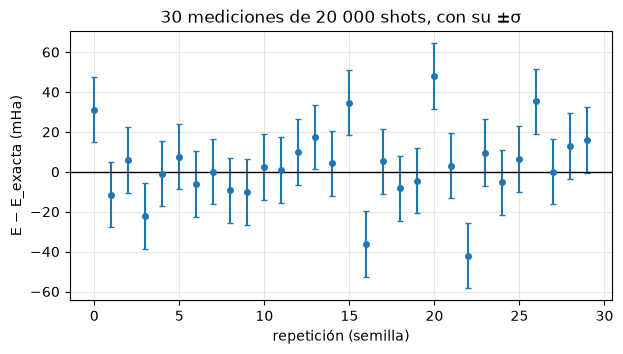

In [4]:
exact_mix = Statevector(qc_mix).expectation_value(H).real
v = validate_sigma(qc_mix, None, H, 20_000, n_repeats=30)
print(f"desviación de las 30 energías: {1e3 * v['std_energies']:.2f} ± {1e3 * v['std_energies_error']:.2f} mHa")
print(f"σ reportada (promedio):         {1e3 * v['mean_sigma']:.2f} mHa")
print(f"cociente:                       {v['ratio']:.2f}")
print(f"media - exacta:                 {1e3 * (v['mean_energy'] - exact_mix):+.2f} mHa "
      f"(error de la media: {1e3 * v['std_energies'] / np.sqrt(30):.2f} mHa)")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(range(30), 1e3 * (v["energies"] - exact_mix), yerr=1e3 * v["sigmas"], fmt="o", ms=4, capsize=2)
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("repetición (semilla)")
ax.set_ylabel("E − E_exacta (mHa)")
ax.set_title("30 mediciones de 20 000 shots, con su ±σ")
ax.grid(alpha=0.3)
inside = np.mean(np.abs(v["energies"] - exact_mix) < v["sigmas"])
print(f"fracción dentro de ±σ: {inside:.0%} (se espera ~68 %)")

Con 30 repeticiones el cociente fluctúa ±13 %. Para una prueba más fina: 300 repeticiones de 5 000 shots (error del cociente ~4 %).

In [5]:
t0 = time.time()
rows = []
for allocation in ("uniform", "weighted"):
    v300 = validate_sigma(qc_mix, None, H, 5_000, n_repeats=300, allocation=allocation, seed0=1000)
    rows.append({"reparto": allocation,
                 "cociente desv/σ": v300["ratio"],
                 "± (error)": v300["std_energies_error"] / v300["mean_sigma"],
                 "sesgo (en errores de la media)": (v300["mean_energy"] - exact_mix) / (v300["std_energies"] / np.sqrt(300))})
print(f"{time.time() - t0:.0f} s")
pd.DataFrame(rows)

279 s


,reparto,cociente desv/σ,± (error),sesgo (en errores de la media)
0,uniform,1.02641,0.04197,0.14610
1,weighted,1.04033,0.04254,0.22866


## 3. Reparto de shots (ítem 3)

- **uniform**: los mismos shots para cada grupo.
- **weighted**: proporcional a $\sum_k |c_k|$ del grupo (el que usamos por defecto).
- **adaptive**: una corrida piloto con el 10 % de los shots estima la dispersión $\sigma_g$ de cada grupo, y el resto se reparte proporcional a $\sigma_g$ (reparto de Neyman, el que minimiza $\sum_g \sigma_g^2/N_g$).

La última columna es cuántos shots harían falta para $\sigma < 1$ mHa, usando $\sigma \propto 1/\sqrt{N}$.

In [6]:
t0 = time.time()
alloc = pd.DataFrame(compare_allocations(qc_mix, None, H, 20_000, n_repeats=30))
alloc["mean_sigma"] *= 1e3
alloc["std_energies"] *= 1e3
alloc = alloc.rename(columns={"mean_sigma": "σ reportada (mHa)", "std_energies": "desv. real (mHa)",
                              "ratio": "cociente", "shots_for_target": "shots para σ<1 mHa"})
print(f"{time.time() - t0:.0f} s")
alloc

52 s


,allocation,shots,mean_energy,σ reportada (mHa),desv. real (mHa),cociente,shots para σ<1 mHa
0,uniform,20000,-0.74611,16.90364,18.99188,1.12354,5714665
1,weighted,20000,-0.74239,16.40850,19.10618,1.16441,5384778
2,adaptive,20000,-0.74672,14.37830,16.59112,1.15390,4134709


Comprobación de $\sigma \propto 1/\sqrt{N}$: σ medida para distintos presupuestos, contra la predicción a partir de 20 000 shots.

shots para σ < 1 mHa: 5384531


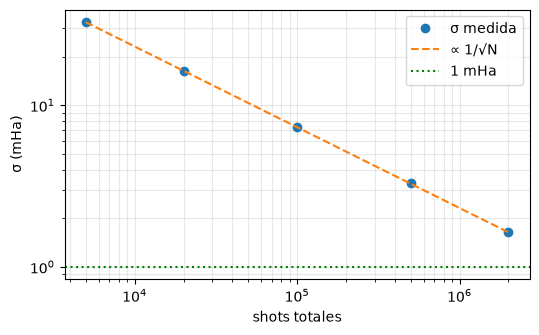

In [7]:
budgets = [5_000, 20_000, 100_000, 500_000, 2_000_000]
sig = [measure_energy(qc_mix, None, H, n, seed=7)["sigma"] for n in budgets]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(budgets, 1e3 * np.array(sig), "o", label="σ medida")
ax.loglog(budgets, 1e3 * sig[1] * np.sqrt(budgets[1] / np.array(budgets)), "--", label="∝ 1/√N")
ax.axhline(1, color="green", ls=":", label="1 mHa")
ax.set_xlabel("shots totales")
ax.set_ylabel("σ (mHa)")
ax.legend()
ax.grid(alpha=0.3, which="both")
print("shots para σ < 1 mHa:", shots_for_sigma(sig[-1], budgets[-1]))

## 4. Indicadores de confiabilidad (ítem 4)

Medidos con el mismo código y con shots: $\langle N\rangle$ (tiene que dar 4), $\langle S^2\rangle$ (0 para el fundamental) y $\mathrm{Var}(H) = \langle H^2\rangle - \langle H\rangle^2$, que es cero solo si el estado es un autoestado. El estado FCI tiene que pasar las tres pruebas; HF tiene N y S² correctos pero varianza positiva, y "mix" falla en las tres.

In [8]:
rows = []
for name, qc in states.items():
    sv = Statevector(qc)
    r = measure_reliability(qc, None, H, p["number_op"], p["s2_op"], 50_000, seed=3)
    rows.append({
        "estado": name,
        "N": f"{r['N']:.3f} ± {r['N_sigma']:.3f}", "N exacto": sv.expectation_value(p["number_op"]).real,
        "S²": f"{r['S2']:.3f} ± {r['S2_sigma']:.3f}", "S² exacto": sv.expectation_value(p["s2_op"]).real,
        "Var(H)": f"{r['variance']:.4f} ± {r['variance_sigma']:.4f}",
        "Var(H) exacta": (sv.expectation_value(H @ H) - sv.expectation_value(H) ** 2).real,
    })
pd.DataFrame(rows)

,estado,N,N exacto,S²,S² exacto,Var(H),Var(H) exacta
0,HF,4.000 ± 0.000,4.00000,-0.027 ± 0.028,0.00000e+00,0.1654 ± 0.0174,1.47954e-01
1,mix,2.362 ± 0.005,2.36309,0.136 ± 0.029,1.50981e-01,0.0750 ± 0.0175,8.94667e-02
2,FCI,4.000 ± 0.000,4.00000,0.077 ± 0.033,-4.26742e-16,0.0429 ± 0.0295,5.06262e-14


## 5. Análisis con los datos reales de Fede (ítem 5)

Los θ óptimos vienen de `results/<kind>_d<d>.json` (optimización con statevector, rama de Fede). Cada punto se volvió a medir **con shots** (`tools/run_measurements.py <kind> 5e6 1e6`: 5 M shots para la energía y 1 M para cada indicador), y los registros quedaron en `results/measured/`.

Antes de medir, `align_theta` corrige el signo de los θ: PySCF devuelve cada orbital con un signo arbitrario que puede cambiar entre corridas, y eso invierte las amplitudes de las excitaciones que lo tocan. Se elige el patrón de signos que reproduce el `e_exact` guardado por Fede.

In [9]:
from analysis import load_records
ns_pipeline = {}
exec(open("../src/pipeline.py").read(), ns_pipeline)
reliability_table = ns_pipeline["reliability_table"]

curves = {kind: load_records(kind, "../results/measured") for kind in ("uccsd_tap", "uccsd")}
for kind, recs in curves.items():
    print(f"{kind}: {len(recs)} puntos, {recs[0]['n_qubits']} qubits, {recs[0]['cz']} cz, {recs[0]['shots']:,} shots por punto")
out = report(curves["uccsd_tap"])

uccsd_tap: 15 puntos, 5 qubits, 428 cz, 5,000,000 shots por punto
uccsd: 15 puntos, 8 qubits, 1108 cz, 5,000,000 shots por punto


### Tabla para la entrega (`uccsd_tap`: UCCSD sobre 5 qubits)

In [10]:
out["table"]

,d (Å),E (Ha),σ (mHa),shots,cz,E_CCSD (Ha),E_FCI (Ha),|E-E_FCI| (mHa),|E_CCSD-E_FCI| (mHa),le gana a CCSD,precisión química
0,0.6,-1.96244,1.26417,5000000,428,-1.96019,-1.96019,2.25062,0.00476,None,False
1,0.7,-2.10669,1.20801,5000000,428,-2.10699,-2.10700,0.30895,0.00424,None,True
2,0.8,-2.16789,1.17381,5000000,428,-2.16756,-2.16756,0.33376,0.00496,None,True
3,0.9,-2.18048,1.15827,5000000,428,-2.18031,-2.18032,0.16511,0.00720,None,True
4,1.0,-2.16665,1.15311,5000000,428,-2.16638,-2.16639,0.26049,0.00793,None,True
5,1.1,-2.13751,1.15812,5000000,428,-2.13798,-2.13797,0.46231,0.00492,None,True
6,1.2,-2.10307,1.16958,5000000,428,-2.10267,-2.10261,0.46256,0.06266,None,True
7,1.4,-2.02669,1.20524,5000000,428,-2.02971,-2.02907,2.37867,0.63647,None,False
8,1.6,-1.96462,1.23231,5000000,428,-1.97057,-1.96756,2.94077,3.01191,None,False
9,1.8,-1.92021,1.23537,5000000,428,-1.93354,-1.92443,4.22097,9.10764,True,False


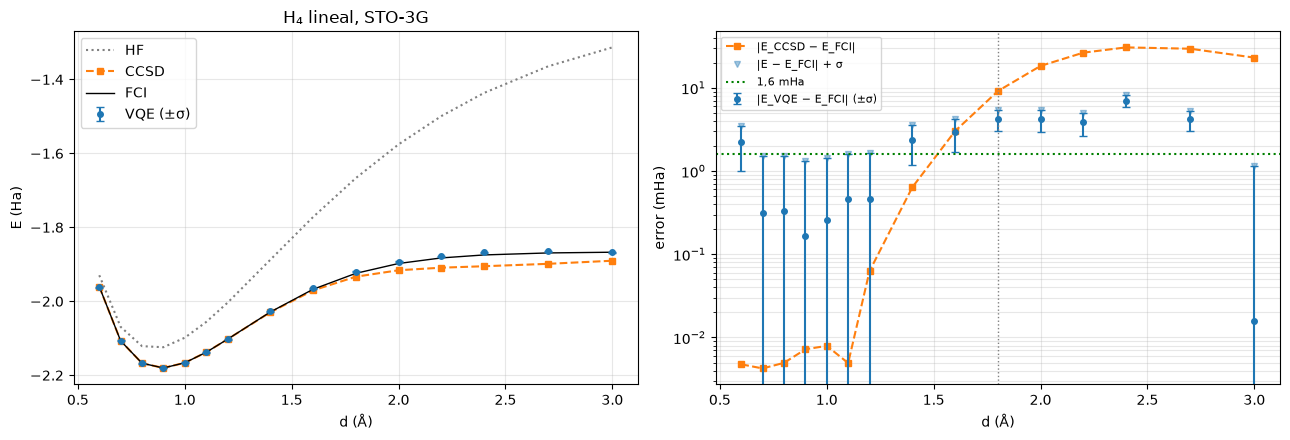

In [11]:
out["figure"]

### $R_e$ y $D_e$

El mínimo de FCI en una grilla densa está en 0,8882 Å.

In [12]:
out["summary"]

,método,R_e (Å),σ R_e (Å),E(R_e) (Ha),D_e (Ha),σ D_e (mHa)
0,VQE,0.88774,0.00576,-2.18068,0.31340,1.58947
1,CCSD,0.88842,0.00000,-2.18049,0.29019,0.00000
2,FCI,0.88843,0.00000,-2.18050,0.31321,0.00000


In [13]:
check = out["beats_ccsd"]
print("le gana a CCSD en todos los puntos con d ≥ 1,8 Å:", check["all_ok"])
print("precisión química en esa zona:", check["all_chemical_accuracy"])
pd.DataFrame(check["points"])

le gana a CCSD en todos los puntos con d ≥ 1,8 Å: True
precisión química en esa zona: False


,d,lhs_mHa,rhs_mHa,ok,chemical_accuracy
0,1.8,5.45634,9.10764,True,False
1,2.0,5.38321,18.30545,True,False
2,2.2,5.03946,26.40768,True,False
3,2.4,8.15835,30.56001,True,False
4,2.7,5.30146,29.44582,True,False
5,3.0,1.13777,23.01300,True,True


### Comparación de los dos ansätze de Fede

Mismo criterio y mismos shots: `uccsd` usa 8 qubits y 1108 `cz`; `uccsd_tap` usa 5 qubits y 428 `cz`.

,ansatz,cz,"le gana a CCSD (d ≥ 1,8)","máx |E−FCI|+σ en d ≥ 1,8 (mHa)"
0,uccsd_tap,428,True,8.15835
1,uccsd,1108,True,5.51688


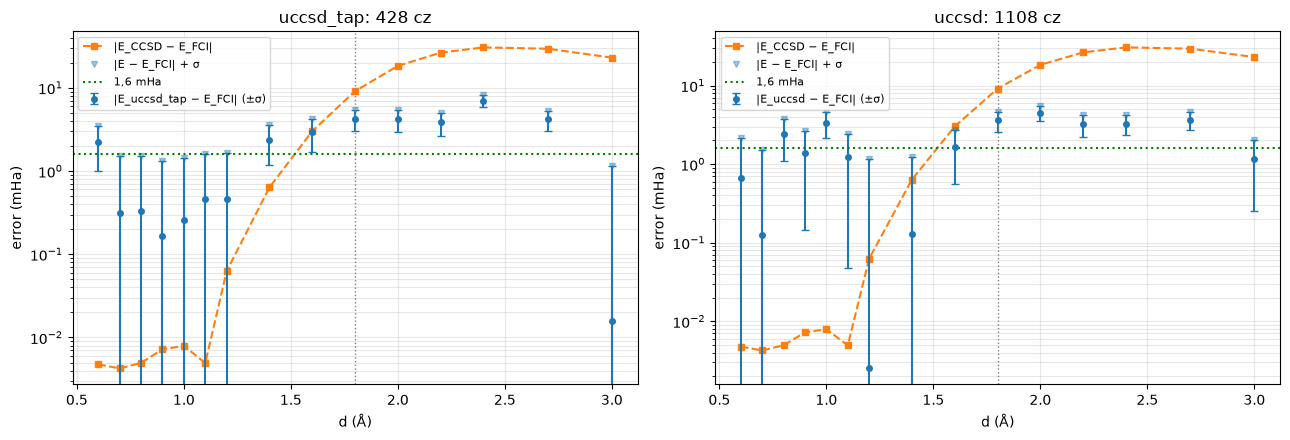

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (kind, recs) in zip(axes, curves.items()):
    plot_errors(recs, ax, label=kind)
    ax.set_title(f"{kind}: {recs[0]['cz']} cz")
fig.tight_layout()
pd.DataFrame([{"ansatz": k, "cz": r[0]["cz"], "le gana a CCSD (d ≥ 1,8)": beats_ccsd(r)["all_ok"],
               "máx |E−FCI|+σ en d ≥ 1,8 (mHa)": max(p["lhs_mHa"] for p in beats_ccsd(r)["points"])}
              for k, r in curves.items()])

### Indicadores de confiabilidad

⟨N⟩ da 4 en todos los puntos y Var(H) es compatible con 0 dentro de su σ. Pero **⟨S²⟩ no da 0 a 3,0 Å** (y en `uccsd`, tampoco a 2,7 Å): el estado optimizado está contaminado con estados de espín alto, que en la disociación tienen casi la misma energía que el singlete. La energía queda cerca de FCI, pero el estado no es el fundamental singlete. Hay que agregar una penalización en S² al optimizar.

In [15]:
for kind, recs in curves.items():
    print(kind)
    display(reliability_table(recs))

uccsd_tap


,d (Å),<N>,σ N,<S²>,σ S²,Var(H) (Ha²),σ Var
0,0.6,4.0,0.0,-0.00009,0.00530,0.01474,0.02905
1,0.7,4.0,0.0,-0.00713,0.00531,-0.03647,0.02255
2,0.8,4.0,0.0,-0.00030,0.00531,-0.01985,0.01840
3,0.9,4.0,0.0,0.00414,0.00533,0.01747,0.01566
4,1.0,4.0,0.0,-0.00102,0.00534,0.01249,0.01384
5,1.1,4.0,0.0,-0.00575,0.00537,0.00335,0.01259
6,1.2,4.0,0.0,-0.00774,0.00542,0.00457,0.01171
7,1.4,4.0,0.0,-0.00787,0.00552,0.00529,0.01072
8,1.6,4.0,0.0,-0.00847,0.00566,0.00370,0.00999
9,1.8,4.0,0.0,0.00971,0.00577,0.00782,0.00935


uccsd


,d (Å),<N>,σ N,<S²>,σ S²,Var(H) (Ha²),σ Var
0,0.6,4.0,0.0,0.00625,0.00634,-0.01072,0.03446
1,0.7,4.0,0.0,0.00739,0.00636,0.01872,0.02621
2,0.8,4.0,0.0,0.00532,0.00638,-0.00383,0.02115
3,0.9,4.0,0.0,-0.00535,0.00641,-0.00921,0.01755
4,1.0,4.0,0.0,0.00467,0.00645,0.01363,0.01497
5,1.1,4.0,0.0,-0.00108,0.00650,0.00324,0.01315
6,1.2,4.0,0.0,-0.00937,0.00657,0.00947,0.01172
7,1.4,4.0,0.0,0.00042,0.00674,0.00678,0.00986
8,1.6,4.0,0.0,-0.00554,0.00696,-0.01684,0.00866
9,1.8,4.0,0.0,-0.00374,0.00716,0.01605,0.00790
